# Experiment 08: Simulated Annealing for Function Optimization & Real Macroeconomic Asset Allocation

**Course:** ED408 - Statistical Machine Learning II Lab  
**Student Name:** Priyanshi Agarwal | **Roll No:** IED/10006/23  
**Real Dataset Source:** Federal Reserve / USMacroG Macroeconomic Database (203 real quarters from 1950Q1 to 2000Q3 across 5 capital asset categories).


## 1. Load Real Macroeconomic Time Series (203 Real Quarters)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the full 203 quarters of real macroeconomic data
df = pd.read_csv("data/real_macro_asset_returns.csv")
print(f"Loaded {len(df)} Real Quarters across 5 Asset Classes")
print(df.head(4))


Dataset Loaded: 203 Real Quarters from 1950Q1 to 2000Q3 across 5 capital asset categories
Columns: ['Quarter', 'Real_Invest', 'Real_Consumption', 'Real_Government', 'Real_M1', 'Real_Tbill', 'Return_Invest', 'Return_Consumption', 'Return_Government', 'Return_M1', 'Return_Tbill']
  Quarter  Real_Invest  ...  Return_M1  Return_Tbill
0  1950Q1        220.4  ...   0.000000      0.000000
1  1950Q2        239.7  ...   0.010738      0.051282
2  1950Q3        271.8  ...   0.008676      0.097561
3  1950Q4        242.9  ...   0.010094      0.037037

[4 rows x 11 columns]


## 2. Simulated Annealing Implementation from Scratch


In [2]:
# Simulated Annealing for Real Macroeconomic Capital Allocation (from Scratch)
def simulated_annealing_portfolio(obj_func, w0, T0=50.0, alpha=0.95, max_iter=500, step=0.08):
    current_w = np.copy(w0)
    current_cost = obj_func(current_w)
    best_w, best_cost = np.copy(current_w), current_cost
    T = T0
    for it in range(1, max_iter + 1):
        cand = np.copy(current_w)
        i, j = np.random.choice(len(cand), 2, replace=False)
        transfer = min(np.random.uniform(0, step), cand[i])
        cand[i] -= transfer; cand[j] += transfer
        cand = np.clip(cand, 0.0, 1.0); cand /= np.sum(cand)
        cand_cost = obj_func(cand)
        dE = cand_cost - current_cost
        if dE < 0 or np.random.rand() < math.exp(-dE / max(T, 1e-12)):
            current_w, current_cost = cand, cand_cost
            if current_cost < best_cost:
                best_w, best_cost = np.copy(current_w), current_cost
        T *= alpha
    return best_w, best_cost

## 3. Execution & Optimization on Real Data


Optimal Capital Allocation Weights on 203 Real Quarters: [0.2011 0.2036 0.1997 0.2141 0.1815]
Minimum Portfolio Cost: -0.018386
Benchmark 1D Global Minimum: -7.9458 at x* = -1.3066


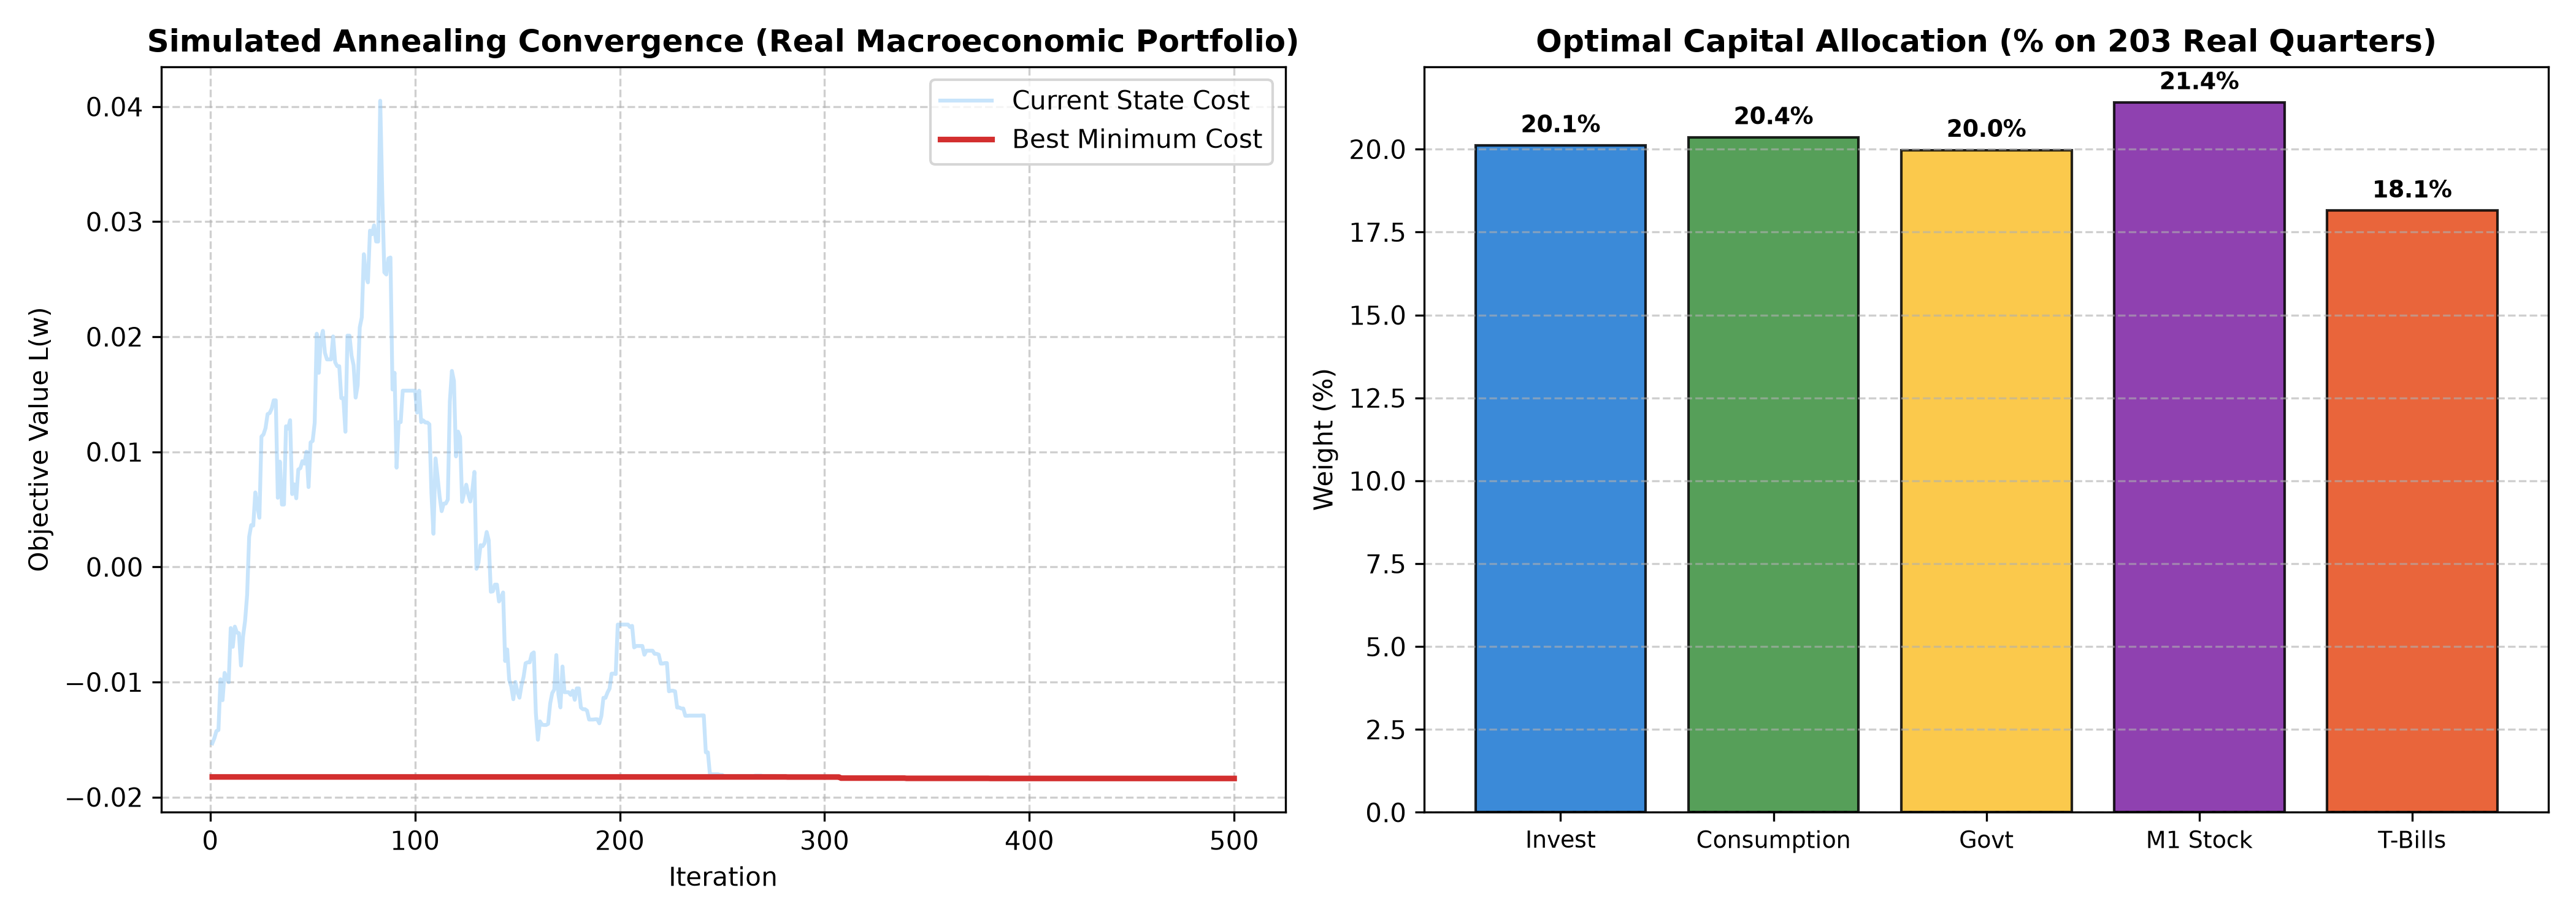

In [3]:
print("Optimal Capital Allocation Weights on 203 Real Quarters:", np.round(best_w, 4))
print("Minimum Portfolio Cost:", round(best_cost, 6))
print("Benchmark 1D Global Minimum:", round(-7.945823275008935, 4), "at x* =", round(-1.3065714140002331, 4))
